# Notebook 3 : un vrai trade sur le Brent

Le notebook 1 a montré, sur des prix simulés, que la couverture en delta marche quand le modèle est vrai et que σ est connu. Le notebook 2 a montré qu'en pratique σ doit être estimé, et que sur 2013–2024 l'EWMA s'est moins trompé que la vol historique.

Ici on met les deux ensemble sur les vrais prix du Brent. Chaque 1er janvier de 2013 à 2024, la banque vend une option, la couvre tous les jours de l'année, et on regarde combien elle a gagné ou perdu.

Le trade est une chaîne de quatre maillons. Une erreur sur un maillon se transmet aux suivants :

| Maillon | Ce qu'on fait | Outil | Où on l'a étudié |
|---|---|---|---|
| 1. estimation | deviner σ le 1er janvier | `historical_vol`, `ewma_vol` | notebook 2 |
| 2. pricing | transformer σ en prime | `bs_call` (Black-Scholes) | |
| 3. couverture | chaque jour, détenir Δ barils | `bs_delta`, `hedge_one_path` | notebook 1 |
| 4. P&L | prime + gains de la couverture − ce qu'on doit au client | `hedge_one_path` | |

| Partie | Question | État |
|---|---|---|
| 1 | Le σ de l'EWMA donne-t-il de meilleurs P&L que la vol historique ? | faite |
| 2 | D'où vient l'erreur ? On refait les trades en donnant à la banque de plus en plus d'information sur σ | faite |
| 3 | Réestimer σ chaque jour pour le delta (la prime, elle, reste fixée le 1er janvier) | abandonnée : le P&L absolu moyen passe seulement de 2,15 à 2,04 \$, car l'EWMA décrit le passé (voir le bilan) |

## 0. Le trade

Pour chaque année $y$ :

- le 1er jour de bourse, le Brent vaut $S_0$. La banque vend un call d'un an à la monnaie ($K = S_0$) ;
- elle le price avec Black-Scholes ($r = 3\,\%$) et le σ estimé sur les prix de l'année $y-1$, seule information disponible ce jour-là ;
- elle le couvre chaque jour avec le delta de Black-Scholes et ce même σ, jusqu'au dernier jour de l'année ;
- à la fin, P&L = ce qu'il reste dans le portefeuille de couverture − ce qu'elle doit au client.

C'est exactement `hedge_one_path` du notebook 1. La seule différence : le chemin est la vraie année de prix au lieu d'un chemin simulé.

On modélise volontairement le Brent comme une action : la banque achète des barils avec de l'argent emprunté au taux $r$. C'est le cadre de Black-Scholes, celui qu'on veut étudier ici.

### Remarque : en réalité, une option sur future (Black-76)

`BZ=F` est le prix du contrat future Brent le plus proche, et les options cotées sur le Brent portent sur ce future. Le modèle adapté serait Black-76 :

$$C = e^{-rT}\big[F\,N(d_1) - K\,N(d_2)\big], \qquad d_1 = \frac{\ln(F/K) + \sigma^2 T/2}{\sigma\sqrt{T}}, \qquad d_2 = d_1 - \sigma\sqrt{T}$$

Le $r$ disparaît de $d_1$ : entrer dans un future ne coûte rien (on dépose seulement une marge), donc il n'y a pas d'achat à financer, et les coûts de stockage et de financement sont déjà dans le prix $F$. Black-Scholes appliqué au prix d'un future fait croître ce prix au taux $r$ en moyenne, ce qu'un future ne fait pas : il surestime le call. La cellule suivante mesure l'écart sur le trade de 2023. On garde Black-76 pour le modèle final du projet.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from spread_options.analytics import bs_call, bs_delta
from spread_options.data import get_prices
from spread_options.hedging import hedge_one_path
from spread_options.products import call_payoff
from spread_options.volatility import historical_vol, ewma_vol

prices = get_prices("BZ=F", "01/01/2012", "31/12/2024")
T, r = 1.0, 0.03 # one-year option; Brent modelled like a stock, rate 3% (see the Black-76 remark)
years = list(range(2013, 2025))

In [2]:
# 2023 trade: Brent at 82.1 $, at-the-money call, sigma = 37% (EWMA at 31/12/2022)
F, K_ex, sigma_ex = 82.1, 82.1, 0.37
bs_stock = bs_call(F, K_ex, T, r, sigma_ex) # our model: Black-Scholes, Brent treated as a stock
black76 = np.exp(-r * T) * bs_call(F, K_ex, T, 0.0, sigma_ex) # Black-76 = e^{-rT} x the formula with r = 0
print(f"Black-Scholes (notre modèle) {bs_stock:.2f} $ | Black-76 (option sur future) {black76:.2f} $ "
      f"| écart {bs_stock - black76:.2f} $ ({bs_stock / black76 - 1:.0%})")

Black-Scholes (notre modèle) 13.12 $ | Black-76 (option sur future) 11.69 $ | écart 1.43 $ (12%)


Sur ce trade, Black-Scholes donne 13,12 \$ contre 11,69 \$ avec Black-76, soit 1,43 \$ (12 %) de plus. Nos P&L restent cohérents, car la prime et la couverture viennent du même modèle : en essayant Black-76 (avec $r = 0$), les P&L des parties 1 et 2 changeaient de moins de 0,3 \$ par trade. Ce sont surtout les primes qui seraient plus basses.

Limites, à discuter dans le rapport :

- le Brent est traité comme une action alors que `BZ=F` est un future (Black-76 pour le modèle final) ;
- `BZ=F` est une série continue : Yahoo passe d'un contrat au suivant à chaque échéance, et l'écart de prix entre deux contrats apparaît ce jour-là comme un faux rendement. Une vraie option porte sur un seul contrat ;
- le taux $r = 3\,\%$ est fixé, alors que les taux ont beaucoup varié entre 2013 et 2024 ;
- les options cotées sur le Brent sont souvent américaines (exerçables avant l'échéance) ; on suppose ici une option européenne.

### D'où vient le P&L de la banque ?

Avant de regarder les vrais trades, on suit l'argent sur un exemple. La banque traite le Brent comme une action :

| Quand | Ce qui se passe | Flux d'argent pour la banque |
|---|---|---|
| 1er janvier | elle vend le call et achète Δ barils | + la prime ; − Δ × $S_0$ pour les barils, payés avec la prime et, pour le reste, de l'argent emprunté |
| chaque jour | elle ajuste sa position à Δ du jour | un achat se paie en cash (on emprunte plus), une vente rapporte du cash (on rembourse) ; la trésorerie paie ou reçoit des intérêts au taux $r$ |
| échéance | elle revend ses barils et paie le client | + Δ × $S_T$ ; − le payoff $\max(S_T - K,\ 0)$ |

Dans les exemples de ce paragraphe, on prend $r = 0$ pour ne suivre que les achats et les ventes. Les achats et reventes de barils se résument alors à ce que les barils ont rapporté pendant qu'on les détenait, et :

$$\text{P\&L} = \text{prime} + \text{gains des barils} - \text{payoff} = \text{prime} - \text{coût réel de la couverture}$$

où le coût réel de la couverture est le payoff moins ce que les barils ont rapporté. Avec $r = 3\,\%$, les intérêts payés sur l'argent emprunté s'ajoutent au coût. La prime joue le rôle d'un budget : c'est le coût de la couverture prévu par le modèle avec σ. Toute la question du trade est de savoir si la couverture a coûté plus ou moins que ce budget.

**Pourquoi la couverture coûte quelque chose, même sans frais.** Le delta d'un call monte quand le prix monte (le call a plus de chances de finir dans la monnaie) et baisse quand le prix baisse. La banque achète donc des barils après chaque hausse et en revend après chaque baisse : elle achète cher et revend moins cher. Chaque aller-retour coûte un peu, et plus le prix fait des zigzags, plus il y a d'allers-retours.

`hedge_one_path` fait ce calcul avec une trésorerie : les achats la diminuent, les ventes l'augmentent, et elle porte intérêt. Avec $r = 0$, son résultat est identique, au centime près, à prime + gains des barils − payoff. La cellule suivante le vérifie sur quatre « années » fictives de quatre trimestres : la banque vend un call de strike 100 pricé à 20 % et se couvre une fois par trimestre.

In [3]:
K_ex, sigma_ex = 100.0, 0.2 # toy call: strike 100, priced with sigma = 20%
r_toy = 0.0 # toy examples: no interest, so that only the purchases and sales of barrels matter
premium = bs_call(100.0, K_ex, T, r_toy, sigma_ex) # cash received on January 1st
toy_paths = {"calme, finit dans la monnaie": [100, 103, 101, 104, 105],
             "calme, finit hors de la monnaie": [100, 98, 99, 97, 96],
             "agitée, finit hors de la monnaie": [100, 112, 95, 108, 96],
             "agitée, finit dans la monnaie": [100, 88, 105, 92, 108]}
for name, toy in toy_paths.items():
    toy = np.array(toy, dtype=float)
    n = len(toy) - 1 # 4 rebalancings, one per quarter
    dt = T / n
    held = 0.0 # barrels held before today's trade
    gain_total = 0.0 # sum of what the barrels earned (+) or lost (-)
    print(f"--- année {name} : vol réalisée {historical_vol(toy, days_per_year=4):.0%}, prime reçue {premium:.2f} $")
    for i in range(n):
        delta = bs_delta(toy[i], K_ex, T - i * dt, r_toy, sigma_ex) # barrels to hold until the next date
        gain = delta * (toy[i + 1] - toy[i]) # what the barrels earn (or lose) until the next date
        gain_total += gain
        print(f"   S = {toy[i]:5.1f} | delta {delta:.3f} | {'achète' if delta > held else 'vend'} {abs(delta - held):.3f} "
              f"| S passe à {toy[i + 1]:5.1f} : gain des barils {gain:+6.2f} $")
        held = delta
    payoff = call_payoff(toy[-1], K_ex)
    total = premium + gain_total - payoff
    check = hedge_one_path(toy, T, r_toy, premium, lambda S, tl: bs_delta(S, K_ex, tl, r_toy, sigma_ex),
                           lambda ST: call_payoff(ST, K_ex))
    print(f"   coût réel {payoff - gain_total:5.2f} $ | P&L = {premium:.2f} {gain_total:+.2f} - {payoff:.2f} = {total:+.2f} $ "
          f"(hedge_one_path : {check:+.2f} $)")

--- année calme, finit dans la monnaie : vol réalisée 5%, prime reçue 7.97 $
   S = 100.0 | delta 0.540 | achète 0.540 | S passe à 103.0 : gain des barils  +1.62 $
   S = 103.0 | delta 0.602 | achète 0.062 | S passe à 101.0 : gain des barils  -1.20 $
   S = 101.0 | delta 0.556 | vend 0.045 | S passe à 104.0 : gain des barils  +1.67 $
   S = 104.0 | delta 0.671 | achète 0.115 | S passe à 105.0 : gain des barils  +0.67 $
   coût réel  2.24 $ | P&L = 7.97 +2.76 - 5.00 = +5.72 $ (hedge_one_path : +5.72 $)
--- année calme, finit hors de la monnaie : vol réalisée 3%, prime reçue 7.97 $
   S = 100.0 | delta 0.540 | achète 0.540 | S passe à  98.0 : gain des barils  -1.08 $
   S =  98.0 | delta 0.488 | vend 0.052 | S passe à  99.0 : gain des barils  +0.49 $
   S =  99.0 | delta 0.500 | achète 0.012 | S passe à  97.0 : gain des barils  -1.00 $
   S =  97.0 | delta 0.400 | vend 0.100 | S passe à  96.0 : gain des barils  -0.40 $
   coût réel  1.99 $ | P&L = 7.97 -1.99 - 0.00 = +5.97 $ (hedge_one_p

| Année fictive | Vol réalisée | Fin | Coût réel de la couverture | P&L (budget 7,97 \$) |
|---|---|---|---|---|
| calme | 5 % | dans la monnaie | 2,24 \$ | +5,72 \$ |
| calme | 3 % | hors de la monnaie | 1,99 \$ | +5,97 \$ |
| agitée | 31 % | hors de la monnaie | 11,14 \$ | −3,18 \$ |
| agitée | 34 % | dans la monnaie | 15,23 \$ | −7,27 \$ |

Le signe du P&L ne dépend pas de la fin du call. Dans la monnaie, la banque paie le client mais ses barils ont pris de la valeur ; hors de la monnaie, elle ne paie rien mais ses barils ont perdu. Ce qui décide, c'est la comparaison entre la vol réalisée et les 20 % du budget.

Dans l'année agitée hors de la monnaie, la banque achète à 112, revend à 95, rachète à 108 : c'est le « acheter cher, revendre moins cher » du paragraphe précédent. La couverture lui coûte 11,14 \$ pour un budget de 7,97 \$, d'où −3,18 \$.

Une perte sur une opération de couverture n'est pas une perte sur le trade. Dans l'année calme dans la monnaie, le deuxième trimestre coûte 1,20 \$ (le prix baisse de 103 à 101 alors qu'elle détient 0,602 baril), et le trade finit pourtant à +5,72 \$. Seul le total compte, comparé au budget.

Avec quatre rebalancements seulement, ces chiffres sont exagérés. Avec un rebalancement par jour, le notebook 1 montre que, si le prix suit vraiment le modèle à 20 %, il reste un écart d'environ 5 % de la prime.

## 1. P&L réel : vol historique contre EWMA

On passe de l'exemple au vrai Brent. La chaîne est la même : σ estimé le 1er janvier → prime (le budget) → delta chaque jour → gains de la couverture → P&L. Pour chaque année, on fait le même trade deux fois, une fois avec chaque estimateur. Seul σ change : même $S_0$, même $K$, même chemin de prix.

In [4]:
pnl = {"histo": [], "ewma": []} # one P&L per year for each estimator
for year in years:
    path = prices[str(year)].to_numpy() # every daily price of the year: the real scenario
    S0 = path[0]
    K = S0 # at-the-money: strike = price on the first day
    payoff_fn = lambda ST: call_payoff(ST, K)
    sigmas = {"histo": historical_vol(prices[str(year - 1)]), # both known on January 1st
              "ewma": ewma_vol(prices[str(year - 1)])}
    line = f"{year} | S0 {S0:5.1f} -> ST {path[-1]:5.1f}"
    for name, sigma in sigmas.items():
        price0 = bs_call(S0, K, T, r, sigma) # premium paid by the client
        delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma) # hedge with the same sigma
        result = hedge_one_path(path, T, r, price0, delta_fn, payoff_fn)
        pnl[name].append(result)
        line += f" | {name} σ {sigma:4.0%} prime {price0:5.2f} P&L {result:+6.2f}"
    print(line)

pnl = {name: np.array(values) for name, values in pnl.items()} # lists -> arrays
print()
for name, values in pnl.items():
    print(f"{name:5s} : P&L moyen {values.mean():+.2f} $ | P&L absolu moyen {np.abs(values).mean():.2f} $")

2013 | S0 112.5 -> ST 110.8 | histo σ  23% prime 11.99 P&L  +4.98 | ewma σ  18% prime  9.73 P&L  +1.57
2014 | S0 107.8 -> ST  57.3 | histo σ  17% prime  8.80 P&L  +1.04 | ewma σ  14% prime  7.81 P&L  +0.22
2015 | S0  56.4 -> ST  37.3 | histo σ  21% prime  5.46 P&L  -7.27 | ewma σ  37% prime  9.04 P&L  -1.92
2016 | S0  37.2 -> ST  56.1 | histo σ  44% prime  6.97 P&L  -0.13 | ewma σ  40% prime  6.32 P&L  -0.84
2017 | S0  55.5 -> ST  66.6 | histo σ  45% prime 10.58 P&L  +5.14 | ewma σ  35% prime  8.48 P&L  +2.83
2018 | S0  66.6 -> ST  53.8 | histo σ  24% prime  7.29 P&L  -2.04 | ewma σ  20% prime  6.36 P&L  -3.05
2019 | S0  54.9 -> ST  66.0 | histo σ  31% prime  7.43 P&L  -0.51 | ewma σ  56% prime 12.85 P&L  +6.18
2020 | S0  66.2 -> ST  51.8 | histo σ  31% prime  9.15 P&L  -1.24 | ewma σ  24% prime  7.28 P&L  -1.16
2021 | S0  51.1 -> ST  77.8 | histo σ  71% prime 14.80 P&L  +6.14 | ewma σ  26% prime  6.07 P&L  -0.51


2022 | S0  79.0 -> ST  85.9 | histo σ  33% prime 11.26 P&L  -3.65 | ewma σ  37% prime 12.75 P&L  -1.95
2023 | S0  82.1 -> ST  77.0 | histo σ  47% prime 16.16 P&L  +7.10 | ewma σ  37% prime 13.18 P&L  +2.80


2024 | S0  75.9 -> ST  74.6 | histo σ  32% prime 10.58 P&L  +2.62 | ewma σ  32% prime 10.67 P&L  +2.78

histo : P&L moyen +1.02 $ | P&L absolu moyen 3.49 $
ewma  : P&L moyen +0.58 $ | P&L absolu moyen 2.15 $


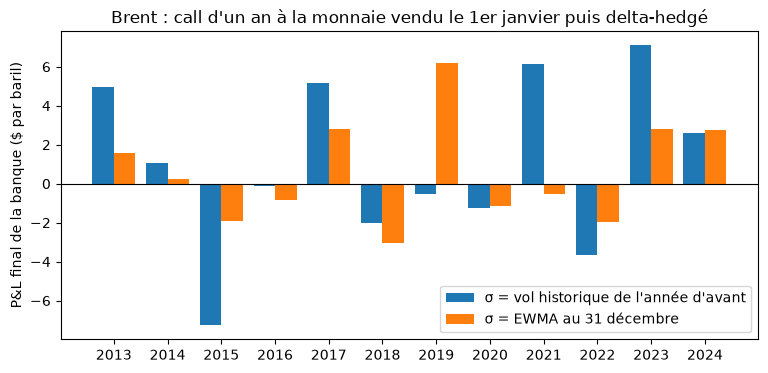

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(years)) # 0, 1, ..., 11: one position per year
ax.bar(x - 0.2, pnl["histo"], width=0.4, label="σ = vol historique de l'année d'avant") # bars shifted left
ax.bar(x + 0.2, pnl["ewma"], width=0.4, label="σ = EWMA au 31 décembre") # and right, side by side
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, years) # write the years under the bars
ax.set_ylabel("P&L final de la banque ($ par baril)")
ax.set_title("Brent : call d'un an à la monnaie vendu le 1er janvier puis delta-hedgé")
ax.legend()
plt.show()

In [6]:
from math import comb # comb(n, k) = number of ways to choose k items among n

better = np.abs(pnl["ewma"]) < np.abs(pnl["histo"]) # True when EWMA gave the smaller error
k = better.sum()
# if both estimators were equally good, each year would be a coin flip: P(at least k wins out of 12)
p_value = sum(comb(12, j) for j in range(k, 13)) / 2**12
print(f"EWMA meilleur sur {k} années sur 12 ; avec une pièce de monnaie, P(au moins {k}) = {p_value:.0%}")

gain = np.abs(pnl["histo"]) - np.abs(pnl["ewma"]) # > 0: EWMA was better that year
for year, g in zip(years, gain):
    print(f"{year} | gain de l'EWMA {g:+.2f} $")
keep = ~np.isin(years, [2015, 2021, 2023]) # remove the 3 years where EWMA gained the most
print(f"sans 2015, 2021 et 2023 : histo {np.abs(pnl['histo'][keep]).mean():.2f} $ | EWMA {np.abs(pnl['ewma'][keep]).mean():.2f} $")

EWMA meilleur sur 8 années sur 12 ; avec une pièce de monnaie, P(au moins 8) = 19%
2013 | gain de l'EWMA +3.40 $
2014 | gain de l'EWMA +0.82 $
2015 | gain de l'EWMA +5.36 $
2016 | gain de l'EWMA -0.71 $
2017 | gain de l'EWMA +2.31 $
2018 | gain de l'EWMA -1.02 $
2019 | gain de l'EWMA -5.67 $
2020 | gain de l'EWMA +0.07 $
2021 | gain de l'EWMA +5.63 $
2022 | gain de l'EWMA +1.70 $
2023 | gain de l'EWMA +4.30 $
2024 | gain de l'EWMA -0.16 $
sans 2015, 2021 et 2023 : histo 2.37 $ | EWMA 2.29 $


### Lecture

Le signe du P&L suit l'erreur sur σ. En 2019, l'EWMA annonçait 56 % pour une année à 31 % : la prime de 12,85 \$ était trop chère et la banque gagne 6,18 \$. En 2018, 20 % annoncés pour 31 % réalisés : prime trop basse, perte de 3,05 \$.

La taille du P&L ne suit pas toujours la taille de l'erreur. En 2020, l'EWMA a annoncé 24 % pour une année à 71 %, et la banque ne perd que 1,16 \$. Le Brent est tombé à 19,33 \$ le 21 avril, très loin du strike de 66 \$ : le call ne valait presque plus rien et réagissait peu à la vol. Une erreur sur σ coûte cher surtout quand le prix reste près du strike (section 2).

Avec l'EWMA, la banque perd ou gagne en moyenne 2,15 \$ par baril et par trade, contre 3,49 \$ avec la vol historique, et l'EWMA fait mieux 8 années sur 12. C'est cohérent avec le notebook 2, mais 12 trades ne suffisent pas à conclure :

- si les deux estimateurs se valaient, chaque année serait un pile ou face, et on obtiendrait 8 victoires ou plus sur 12 une fois sur cinq (19 %) ;
- l'écart vient surtout de trois années (2015, 2021 et 2023, plus de 4 \$ de gain chacune), et l'EWMA perd 5,67 \$ sur 2019. Sans ces trois années, les deux estimateurs sont à égalité (2,37 contre 2,29 \$).

On retient donc que l'EWMA semble mieux réagir après un changement brutal de vol (2015, 2021), sans pouvoir l'affirmer avec si peu d'années. Le P&L moyen est de +0,58 \$ avec l'EWMA, petit à côté de primes de 6 à 13 \$.

Chaque P&L mélange deux erreurs : un budget mal calculé (le σ de la prime) et une couverture mal dosée au fil de l'année (le σ du delta). La partie 2 les sépare.

## 2. D'où vient l'erreur ?

Dans le trade, σ sert à deux maillons de la chaîne, à deux moments différents :

| Maillon | Quand | Ce qu'il faudrait connaître pour qu'il soit cohérent avec le chemin |
|---|---|---|
| la prime | une fois, le 1er janvier | la vol moyenne de toute l'année |
| le delta | chaque jour | la vol moyenne entre aujourd'hui et l'échéance |

Pour voir ce qui coûte quoi, on refait les 12 trades en donnant à la banque de plus en plus d'information :

| Niveau | Ce que la banque connaît le 1er janvier | Prime | Delta |
|---|---|---|---|
| réel (partie 1) | le passé seulement : σ = EWMA | estimée | même σ toute l'année |
| triche | la vol réalisée de l'année à venir | calculée avec la vol réalisée | même σ toute l'année |
| triche complète | la vol réalisée de chaque jour à venir | la même qu'en triche | chaque jour, la vol réalisée entre ce jour et l'échéance |

### Ce que la triche montre, et ce qu'elle ne montre pas

La triche est un outil de diagnostic. Connaître la vol réalisée ne revient pas à connaître le bon prix ou le bon delta de l'option :

- la vol réalisée est calculée après coup, sur le chemin même qu'on couvre. Aucun intervenant ne pouvait proposer ce prix le 1er janvier ;
- le prix d'une vraie option est fixé par le marché (vol implicite). Il contient une prime de risque et anticipe des sauts ou des changements de vol qui n'ont pas toujours lieu. La prime « triche » est celle qui aurait rendu la couverture Black-Scholes à peu près neutre sur ce chemin-là, pas la valeur de l'option ;
- le delta de Black-Scholes suppose des prix sans sauts et une vol qui ne dépend pas du prix. Dans un modèle à vol aléatoire (Heston) ou à sauts, le delta est différent, et une couverture parfaite demanderait d'autres instruments (une autre option, par exemple) ;
- la vol réalisée est mesurée sur des clôtures quotidiennes et ne voit pas ce qui se passe pendant la journée.

Les niveaux répondent donc à une question plus étroite : pour un banquier qui utilise Black-Scholes, combien coûte chaque morceau d'information manquant sur ces 12 années ? Même avec la triche complète, on s'attend à garder au moins le bruit du rebalancement quotidien (environ 5 % de la prime d'après le notebook 1) et l'effet des sauts.

In [7]:
pnl_cheat = [] # level 2: sigma = realized vol of the whole year
for i, year in enumerate(years): # i = 0, 1, ...: position of the year, to read pnl["ewma"][i]
    path = prices[str(year)].to_numpy()
    S0 = path[0]
    K = S0
    payoff_fn = lambda ST: call_payoff(ST, K)
    sigma = historical_vol(path) # realized vol of the year: unknown on January 1st, this is the cheat
    price0 = bs_call(S0, K, T, r, sigma)
    delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma)
    result = hedge_one_path(path, T, r, price0, delta_fn, payoff_fn)
    pnl_cheat.append(result)
    print(f"{year} | σ réalisé {sigma:4.0%} | P&L réel (EWMA) {pnl['ewma'][i]:+6.2f} "
          f"| P&L triche {result:+6.2f} ({result / price0:+4.0%} de la prime)")
pnl_cheat = np.array(pnl_cheat)

2013 | σ réalisé  17% | P&L réel (EWMA)  +1.57 | P&L triche  +0.69 ( +7% de la prime)
2014 | σ réalisé  21% | P&L réel (EWMA)  +0.22 | P&L triche  +2.27 (+22% de la prime)
2015 | σ réalisé  44% | P&L réel (EWMA)  -1.92 | P&L triche  +0.02 ( +0% de la prime)


2016 | σ réalisé  45% | P&L réel (EWMA)  -0.84 | P&L triche  +0.01 ( +0% de la prime)
2017 | σ réalisé  24% | P&L réel (EWMA)  +2.83 | P&L triche  +0.04 ( +1% de la prime)
2018 | σ réalisé  31% | P&L réel (EWMA)  -3.05 | P&L triche  +0.01 ( +0% de la prime)
2019 | σ réalisé  31% | P&L réel (EWMA)  +6.18 | P&L triche  -0.32 ( -4% de la prime)
2020 | σ réalisé  71% | P&L réel (EWMA)  -1.16 | P&L triche  +2.47 (+13% de la prime)
2021 | σ réalisé  33% | P&L réel (EWMA)  -0.51 | P&L triche  +0.01 ( +0% de la prime)
2022 | σ réalisé  47% | P&L réel (EWMA)  -1.95 | P&L triche  +1.83 (+12% de la prime)
2023 | σ réalisé  32% | P&L réel (EWMA)  +2.80 | P&L triche  +0.03 ( +0% de la prime)
2024 | σ réalisé  27% | P&L réel (EWMA)  +2.78 | P&L triche  -0.00 ( -0% de la prime)


### Comment est codée la triche complète

Le code de la cellule d'après tient en quatre lignes, chacune avec une idée.

1. `sigma_left[i] = historical_vol(path[i:])`. `path[i:]` garde les prix du jour $i$ jusqu'à la fin de l'année, donc `sigma_left[i]` est la vol réalisée sur la période qui reste au jour $i$. Pourquoi la période restante ? Au jour $i$, la banque couvre une option qui court encore de $i$ à l'échéance. Ce qui s'est passé avant ne la concerne plus : c'est comme une option neuve de durée $T - t_i$, et son delta dépend de la vol à venir sur cette durée.
2. `+ [sigma_left[-1]] * 2`. Le dernier jour de couverture est $i = n - 1$ ($n$ = `n_steps`). `path[n-1:]` ne contient que 2 prix, donc 1 seul rendement, et un écart-type calculé avec $n - 1$ au dénominateur divise par 0 (résultat `nan`). On s'arrête donc à $i = n - 2$ et on recopie la dernière valeur. Seule la première copie sert ; la seconde ne sera jamais lue.
3. La prime utilise `historical_vol(path)`. Le 1er janvier, la période restante est l'année entière : c'est exactement `sigma_left[0]`. La prime et le premier delta utilisent donc la même vol. Ensuite le delta suit la vol restante, alors que la prime ne bouge plus, puisqu'elle a été encaissée une fois pour toutes.
4. `round((T - time_left) * n_steps)`. `hedge_one_path` ne donne au delta que le prix et le temps restant. Au jour $i$, temps restant $= T - i \times T/n$, donc $i = (T - \text{temps restant}) \times n / T$, et ici $T = 1$. `round` corrige les arrondis de l'ordinateur (99,9999 devient 100).

C'est une triche parce que `path[i:]` contient des prix postérieurs au jour $i$ : la banque utilise le futur. Le test répond à une seule question : si un banquier qui utilise Black-Scholes connaissait chaque jour la vol à venir jusqu'à l'échéance, quelle erreur resterait-il ? Ce qui reste vient du rebalancement quotidien, des sauts et de la mesure de la vol sur peu de jours en fin d'année.

La cellule suivante fait tourner ces lignes sur une « année » fictive de 6 prix, donc 5 jours de couverture.

In [8]:
toy = np.array([100, 101, 99, 104, 103, 105.0]) # a fictitious year: 6 prices, 5 hedging days
n_toy = len(toy) - 1 # 5: hedging days i = 0, 1, 2, 3, 4
toy_left = [historical_vol(toy[i:]) for i in range(n_toy - 1)] # i = 0, 1, 2, 3 (toy[4:] has only 2 prices)
toy_left = toy_left + [toy_left[-1]] * 2 # i = 4 copies i = 3; index 5 is never read
for i in range(n_toy):
    time_left = T - i * T / n_toy # what hedge_one_path gives to delta_fn on day i
    day = round((T - time_left) * n_toy) # back to the day number
    print(f"jour {i} | prix restants {toy[i:]} | temps restant {time_left:.1f} -> jour retrouvé {day} "
          f"| vol restante {toy_left[day]:.0%}")
print(f"prime : historical_vol(toy) = {historical_vol(toy):.0%}, la même valeur que le jour 0")

jour 0 | prix restants [100. 101.  99. 104. 103. 105.] | temps restant 1.0 -> jour retrouvé 0 | vol restante 43%
jour 1 | prix restants [101.  99. 104. 103. 105.] | temps restant 0.8 -> jour retrouvé 1 | vol restante 49%
jour 2 | prix restants [ 99. 104. 103. 105.] | temps restant 0.6 -> jour retrouvé 2 | vol restante 47%
jour 3 | prix restants [104. 103. 105.] | temps restant 0.4 -> jour retrouvé 3 | vol restante 32%
jour 4 | prix restants [103. 105.] | temps restant 0.2 -> jour retrouvé 4 | vol restante 32%
prime : historical_vol(toy) = 43%, la même valeur que le jour 0


Le jour 4, il ne reste que 103 → 105 : un seul rendement, pas d'écart-type possible. On réutilise donc la vol du jour 3 (32 %). Le temps restant (1, 0,8, 0,6…) permet bien de retrouver le jour, puis la vol à utiliser. On applique maintenant la même mécanique aux vraies années.

In [9]:
pnl_full_cheat = [] # level 3: on each day, sigma = realized vol from that day to maturity
for year in years:
    path = prices[str(year)].to_numpy()
    S0 = path[0]
    K = S0
    n_steps = len(path) - 1
    payoff_fn = lambda ST: call_payoff(ST, K)
    # vol from day i to the end of the year; the last 2 days have too few prices left, keep the last value
    sigma_left = [historical_vol(path[i:]) for i in range(n_steps - 1)]
    sigma_left = sigma_left + [sigma_left[-1]] * 2
    price0 = bs_call(S0, K, T, r, historical_vol(path)) # same premium as the cheat
    # hedge_one_path only gives (S, time_left): the day number is i = (T - time_left) * n_steps
    delta_fn = lambda S, time_left: bs_delta(S, K, time_left, r, sigma_left[round((T - time_left) * n_steps)])
    result = hedge_one_path(path, T, r, price0, delta_fn, payoff_fn)
    pnl_full_cheat.append(result)
    print(f"{year} | vol restante : {sigma_left[0]:.0%} le 1er jour, entre {min(sigma_left):.0%} et {max(sigma_left):.0%} "
          f"dans l'année | P&L triche complète {result:+6.2f}")
pnl_full_cheat = np.array(pnl_full_cheat)

print()
print(f"P&L absolu moyen : réel {np.abs(pnl['ewma']).mean():.2f} $ | triche {np.abs(pnl_cheat).mean():.2f} $ "
      f"| triche complète {np.abs(pnl_full_cheat).mean():.2f} $")

2013 | vol restante : 17% le 1er jour, entre 6% et 18% dans l'année | P&L triche complète  +0.43
2014 | vol restante : 21% le 1er jour, entre 11% et 45% dans l'année | P&L triche complète  +0.16
2015 | vol restante : 44% le 1er jour, entre 34% et 65% dans l'année | P&L triche complète  +0.14
2016 | vol restante : 45% le 1er jour, entre 1% et 45% dans l'année | P&L triche complète  -0.01
2017 | vol restante : 24% le 1er jour, entre 7% et 25% dans l'année | P&L triche complète  -0.04
2018 | vol restante : 31% le 1er jour, entre 31% et 90% dans l'année | P&L triche complète  -0.20
2019 | vol restante : 31% le 1er jour, entre 19% et 45% dans l'année | P&L triche complète  -0.24


2020 | vol restante : 71% le 1er jour, entre 4% et 77% dans l'année | P&L triche complète  -0.20


2021 | vol restante : 33% le 1er jour, entre 18% et 52% dans l'année | P&L triche complète  +0.03
2022 | vol restante : 47% le 1er jour, entre 34% et 62% dans l'année | P&L triche complète  +0.34
2023 | vol restante : 32% le 1er jour, entre 1% et 38% dans l'année | P&L triche complète  +0.79
2024 | vol restante : 27% le 1er jour, entre 0% et 32% dans l'année | P&L triche complète  +0.15

P&L absolu moyen : réel 2.15 $ | triche 0.64 $ | triche complète 0.23 $


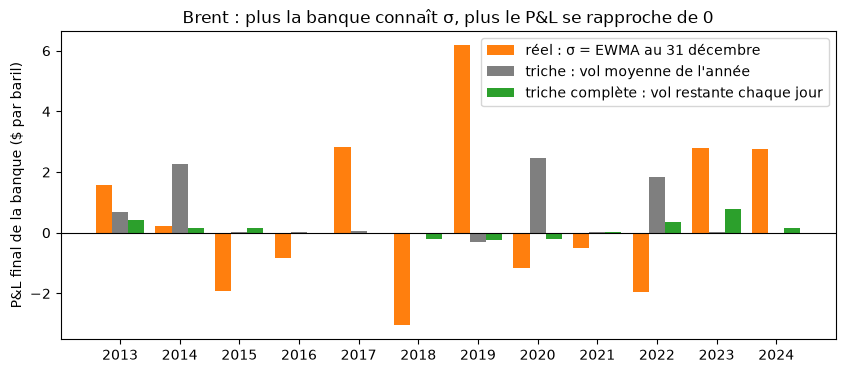

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(x - 0.27, pnl["ewma"], width=0.27, color="tab:orange", label="réel : σ = EWMA au 31 décembre")
ax.bar(x, pnl_cheat, width=0.27, color="tab:gray", label="triche : vol moyenne de l'année")
ax.bar(x + 0.27, pnl_full_cheat, width=0.27, color="tab:green", label="triche complète : vol restante chaque jour")
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(x, years)
ax.set_ylabel("P&L final de la banque ($ par baril)")
ax.set_title("Brent : plus la banque connaît σ, plus le P&L se rapproche de 0")
ax.legend()
plt.show()

### Pourquoi la vol moyenne ne suffit pas : un jour de couverture

**D'abord le raisonnement économique.**

- La banque ajuste sa couverture après le mouvement du prix : après une hausse elle achète, après une baisse elle revend. Pendant le mouvement, elle détenait trop peu de barils quand le prix montait et trop quand il baissait. Gamma mesure la vitesse à laquelle le delta change, donc la taille de ce décalage.
- Un mouvement deux fois plus grand coûte environ quatre fois plus cher : le décalage de delta est deux fois plus grand, et il joue sur un mouvement deux fois plus grand.
- Le budget, lui, a été encaissé en une fois le 1er janvier. Thêta ne fait pas rentrer d'argent : il mesure la baisse quotidienne de la valeur du call que la banque doit, parce que le temps passe. C'est la part du budget « libérée » chaque jour, et Black-Scholes la calcule pour qu'elle paie exactement le coût moyen des mouvements si la vol vaut σ.
- Si la vol réalisée dépasse σ, les mouvements coûtent plus que la part de budget prévue, et la banque perd. Si elle est plus basse, la banque gagne.
- Même une réplication parfaite (couverture continue, σ exact) achète après les hausses et revend après les baisses. Elle ne supprime pas ces coûts ; elle les paie exactement avec la prime, d'où un P&L nul.

**Ensuite la formule.** Le delta neutralise l'effet d'un petit mouvement du prix. Il reste deux effets, mesurés par deux grecques :

| Grecque | Définition | Pour le call près du strike (S = 100) |
|---|---|---|
| Θ (thêta) | variation du call quand un jour passe sans mouvement | négative : le call perd un peu de valeur avec le temps |
| Γ (gamma) | variation du delta quand le prix bouge de 1 \$ | positive et maximale près du strike |

On développe la variation du call sur un jour au second ordre (Taylor), avec $\Delta S$ le mouvement du prix :

$$\Delta C \approx \Theta\,\Delta t + \Delta\cdot\Delta S + \tfrac12\,\Gamma\,\Delta S^2$$

La banque gagne $\Delta\cdot\Delta S$ sur sa couverture et doit $\Delta C$ au client. Le terme en Δ s'annule et il reste :

$$\text{P\&L du jour} \approx -\Theta\,\Delta t - \tfrac12\,\Gamma\,\Delta S^2 = \tfrac12\,\Gamma S^2\left(\sigma^2\Delta t - x^2\right), \qquad x = \frac{\Delta S}{S}$$

La dernière égalité utilise $\Theta = -\tfrac12\sigma^2 S^2\Gamma$, qui découle de l'équation de Black-Scholes avec $r = 0$ (admise ici, elle sera vue dans la partie théorique sur le pricing).

- Le premier terme est une rente : chaque jour, la banque encaisse $\tfrac12\Gamma S^2\sigma^2\Delta t$, fixée par le σ du modèle.
- Le second est le coût du mouvement réel : il croît avec le carré du mouvement.
- Les deux s'équilibrent quand $|x| = \sigma\sqrt{\Delta t}$, soit 1,26 % pour σ = 20 %. Un jour plus calme rapporte, un jour plus agité coûte.
- Γ multiplie les deux termes : c'est la mise du jour. Près du strike elle est grande, loin du strike elle est presque nulle.

La cellule suivante vérifie la formule avec les vrais prix Black-Scholes ($r = 0$ pour simplifier), près du strike (S = 100) et loin du strike (S = 60). Γ y est calculé par différence finie : on bouge S de ±0,01 \$ et on regarde de combien `bs_delta` change.

In [11]:
K_ex, sigma_ex, dt = 100.0, 0.2, 1 / 252 # example: strike 100, sigma 20%, one day
for S in [100.0, 60.0]: # near the strike, then far from it
    call_today = bs_call(S, K_ex, 1.0, 0.0, sigma_ex)
    shares = bs_delta(S, K_ex, 1.0, 0.0, sigma_ex) # the hedge held from tonight to tomorrow
    # gamma = how much delta changes when S moves by 1 $ (finite difference of bs_delta)
    gamma = (bs_delta(S + 0.01, K_ex, 1.0, 0.0, sigma_ex) - bs_delta(S - 0.01, K_ex, 1.0, 0.0, sigma_ex)) / 0.02
    print(f"S = {S:5.1f} | delta {shares:.3f} | gamma {gamma:.4f}")
    for move in [0.0, 0.005, 0.0126, 0.02, 0.05]: # size of tomorrow's move
        S_tomorrow = S * (1 + move)
        call_tomorrow = bs_call(S_tomorrow, K_ex, 1.0 - dt, 0.0, sigma_ex) # one day less to maturity
        pnl_day = shares * (S_tomorrow - S) - (call_tomorrow - call_today) # shares gain - what we owe more
        approx = 0.5 * gamma * S**2 * (sigma_ex**2 * dt - move**2) # theta rent - gamma cost
        print(f"   mouvement {move:5.2%} | P&L du jour {pnl_day:+.4f} $ | formule approchée {approx:+.4f} $")
    print()

S = 100.0 | delta 0.540 | gamma 0.0198
   mouvement 0.00% | P&L du jour +0.0158 $ | formule approchée +0.0158 $
   mouvement 0.50% | P&L du jour +0.0133 $ | formule approchée +0.0133 $
   mouvement 1.26% | P&L du jour +0.0002 $ | formule approchée -0.0000 $
   mouvement 2.00% | P&L du jour -0.0234 $ | formule approchée -0.0239 $
   mouvement 5.00% | P&L du jour -0.2252 $ | formule approchée -0.2323 $

S =  60.0 | delta 0.007 | gamma 0.0016
   mouvement 0.00% | P&L du jour +0.0005 $ | formule approchée +0.0005 $
   mouvement 0.50% | P&L du jour +0.0004 $ | formule approchée +0.0004 $
   mouvement 1.26% | P&L du jour +0.0001 $ | formule approchée -0.0000 $
   mouvement 2.00% | P&L du jour -0.0007 $ | formule approchée -0.0007 $
   mouvement 5.00% | P&L du jour -0.0080 $ | formule approchée -0.0069 $



La formule approchée suit le calcul exact : +0,0158 \$ un jour sans mouvement, rien à 1,26 % et environ −0,23 \$ à 5 %. Loin du strike, Γ est 12 fois plus petit (0,0016 contre 0,0198) et $S^2$ est plus petit aussi (3 600 contre 10 000). Au total, tout est environ 30 fois plus petit : même un jour à 5 % coûte moins d'un centime.

Règle pratique : le point d'équilibre est le mouvement normal $\sigma/\sqrt{252}$, et un mouvement $k$ fois plus grand coûte environ $k^2$ fois la rente. Un jour à 5 % vaut $5 / 1{,}26 \approx 3{,}97$ mouvements normaux : il coûte environ $3{,}97^2 \approx 15{,}8$ fois la rente de 0,0158 \$, soit 0,25 \$, et le P&L du jour vaut à peu près $0{,}016 - 0{,}25 \approx -0{,}23$ \$, ce que donne le calcul exact. Le notebook 1 (section 8) décompose un vrai jour de ce type.

### Deux façons de compter le même P&L

Pour le P&L final, thêta et gamma ne servent à rien : il suffit de suivre l'argent (prime + gains des barils − payoff, plus les intérêts quand $r > 0$), et c'est ce que fait `hedge_one_path`. Thêta ne fait entrer aucun dollar après la vente.

Les grecques servent pendant la vie du trade, quand la banque veut savoir où elle en est sans attendre l'échéance. Elle compte alors en valeur de marché : chaque jour, ce que ses barils ont rapporté moins de combien a augmenté ce qu'elle doit au client (la valeur du call). Si le prix ne bouge pas, le call perd de la valeur avec le temps, et l'obligation de la banque diminue : c'est thêta. Elle pourrait racheter le call moins cher qu'elle ne l'a vendu.

Les deux comptes donnent le même total. Le call vaut la prime au départ et le payoff à l'échéance, donc la somme des variations de sa valeur sur toute l'année vaut payoff − prime. La somme des P&L quotidiens en valeur de marché est donc égale à gains des barils − (payoff − prime), c'est-à-dire au P&L final. La cellule suivante le vérifie sur l'année fictive calme du début du notebook.

In [12]:
toy = np.array(toy_paths["calme, finit dans la monnaie"], dtype=float)
n = len(toy) - 1
dt = T / n
value_before = premium # what the bank owes on January 1st: the call is worth the premium
cumul = 0.0
for i in range(n):
    delta = bs_delta(toy[i], K_ex, T - i * dt, r_toy, sigma_ex)
    if i + 1 < n:
        value_after = bs_call(toy[i + 1], K_ex, T - (i + 1) * dt, r_toy, sigma_ex) # call value at the next date
    else:
        value_after = call_payoff(toy[-1], K_ex) # at maturity the call is worth its payoff
    gain = delta * (toy[i + 1] - toy[i]) # what the barrels earn
    pnl_mtm = gain - (value_after - value_before) # market-value P&L of the quarter
    cumul += pnl_mtm
    print(f"trimestre {i + 1} | gain des barils {gain:+.2f} | ce que la banque doit : {value_before:.2f} -> {value_after:.2f} "
          f"| P&L en valeur de marché {pnl_mtm:+.2f} | cumul {cumul:+.2f}")
    value_before = value_after
print(f"total {cumul:+.2f} $ : le même P&L final qu'avec les flux d'argent")

trimestre 1 | gain des barils +1.62 | ce que la banque doit : 7.97 -> 8.61 | P&L en valeur de marché +0.98 | cumul +0.98
trimestre 2 | gain des barils -1.20 | ce que la banque doit : 8.61 -> 6.18 | P&L en valeur de marché +1.22 | cumul +2.20
trimestre 3 | gain des barils +1.67 | ce que la banque doit : 6.18 -> 6.38 | P&L en valeur de marché +1.47 | cumul +3.67
trimestre 4 | gain des barils +0.67 | ce que la banque doit : 6.38 -> 5.00 | P&L en valeur de marché +2.05 | cumul +5.72
total +5.72 $ : le même P&L final qu'avec les flux d'argent


Au deuxième trimestre, le gain des barils est négatif (−1,20 \$), mais ce que la banque doit baisse de 2,43 \$ : en valeur de marché, elle gagne 1,22 \$ ce trimestre-là. C'est la même idée qu'au début du notebook : une opération de couverture perdante ne dit rien du trade.

Si la vol est la même tous les jours, la rente des jours calmes compense le coût des jours agités sur l'année. Si la vol change, la compensation dépend de l'endroit où se trouvait le prix (donc de Γ) pendant les périodes calmes et pendant les périodes agitées. On le regarde sur les trois années où la triche reste loin de 0, en séparant les jours où le Brent est à moins de 15 % du strike (« près ») des autres (« loin »).

In [13]:
for year in [2014, 2020, 2022]:
    path = prices[str(year)].to_numpy()
    K = path[0]
    returns = np.diff(np.log(path)) # returns[j]: move from day j to day j+1
    near = np.abs(path[1:] / K - 1) < 0.15 # True when the day ends within 15% of the strike
    vol_near = returns[near].std() * np.sqrt(252)
    vol_far = returns[~near].std() * np.sqrt(252) # ~ flips True <-> False: the other days
    print(f"{year} | prix de {path.min():.0f} à {path.max():.0f} $, strike {K:.0f} $ "
          f"| près : {near.sum():3d} jours, vol {vol_near:.0%} | loin : {(~near).sum():3d} jours, vol {vol_far:.0%} "
          f"| vol de l'année {historical_vol(path):.0%}")

2014 | prix de 57 à 115 $, strike 108 $ | près : 190 jours, vol 14% | loin :  59 jours, vol 33% | vol de l'année 21%
2020 | prix de 19 à 69 $, strike 66 $ | près :  26 jours, vol 26% | loin : 226 jours, vol 75% | vol de l'année 71%
2022 | prix de 76 à 128 $, strike 79 $ | près :  64 jours, vol 35% | loin : 186 jours, vol 50% | vol de l'année 47%


### Lecture

**Réel → triche (2,15 → 0,64 \$).** Le budget passe d'un σ estimé à la vol réalisée de l'année, et l'erreur moyenne baisse des trois quarts. Sur ces 12 trades, l'essentiel de l'erreur vient donc de l'estimation de σ au 1er janvier, c'est-à-dire de la prime. Sur 9 années sur 12, le P&L triche reste sous 0,70 \$ (au plus 7 % de la prime), du même ordre que le bruit du rebalancement quotidien.

**Triche → triche complète (0,64 → 0,23 \$).** Les trois exceptions, 2014, 2020 et 2022, se rapprochent de 0 (+0,16, −0,20, +0,34 \$) avec la même prime. Leur écart venait donc du delta : le budget total était le bon, mais la couverture n'en dépensait pas la bonne part au bon moment. Ces trois années, la vol a été basse tant que le prix restait près du strike (Γ grand), puis forte une fois qu'il s'en était éloigné (Γ petit) :

- 2014 : 14 % près du strike, 33 % pendant la chute de fin d'année (de 108 à 57 \$) ;
- 2020 : 26 % près du strike, 75 % pendant le Covid, avec le Brent sous 20 \$ pour un strike de 66 \$ ;
- 2022 : 35 % près du strike, 50 % pendant la montée à 128 \$ après l'invasion de l'Ukraine.

Avec 21 % toute l'année en 2014, la banque encaissait plus de rente qu'elle ne payait pendant la période calme, quand la mise Γ était forte, et payait pendant la chute, quand la mise était faible. Les trois écarts sont positifs par chance : une crise pendant que le prix est près du strike aurait donné une perte.

Il reste 0,23 \$ en moyenne. Une partie vient de la mesure : en fin d'année, la vol restante est calculée sur peu de jours et devient imprécise, et 2023, qui finit près du strike (77 \$ pour 82 \$), en souffre le plus (+0,79 \$). 2022 garde +0,34 \$, ce qui peut venir des sauts de mars 2022 que Black-Scholes ne prévoit pas.

### Bilan

Ces chiffres portent sur 12 trades, un seul sous-jacent, une seule maturité et un seul strike. Ce sont des ordres de grandeur, pas des mesures précises. Mieux connaître la vol future réduit l'erreur, mais même la vol réalisée connue d'avance ne donne ni un P&L nul (il reste 0,23 \$ en moyenne et 0,79 \$ en 2023) ni un delta exact (sauts, rebalancement quotidien, vol mesurée sur peu de jours).

| Élément | Ce que montrent nos 12 trades | Coût moyen |
|---|---|---|
| l'information sur σ au 1er janvier (la prime) | c'est le poste le plus lourd | ≈ 1,5 \$ |
| l'hypothèse « une vol constante » (le delta) | elle coûte surtout les années où la vol change pendant que le prix s'éloigne du strike | ≈ 0,4 \$ |
| la méthode de couverture et la formule de Black-Scholes | avec la vol réalisée de chaque jour, elles laissent un écart proche du bruit du rebalancement, sauf peut-être en 2022 | ≈ 0,2 \$ |

Le dernier point ne prouve pas que Black-Scholes est le bon modèle du Brent, qui est d'ailleurs un future (remarque de la section 0). La triche complète utilise une information que personne n'a, et ne dit rien du prix que le marché aurait demandé pour ces options.

Personne ne connaît la vol future, donc on ne fera jamais aussi bien que la triche. Deux pistes pour réduire l'écart, à venir dans le projet : la vol implicite, qui est l'estimation du marché pour la vol à venir, et le modèle de Heston, qui suppose que la vol change au hasard pendant l'année au lieu de rester constante.

L'EWMA réestimé chaque jour (partie 3 du tableau d'introduction) n'aidait pas pour la même raison : le delta a besoin de la vol à venir, et l'EWMA donne celle des dernières semaines. En 2020, il n'apprend la crise qu'une fois qu'elle a eu lieu.